<a href="https://colab.research.google.com/github/ritashreemukherjee123/Project-1-Applied-Search-Intelligence-Google-Search-Ranking-Discoverability.-/blob/main/work/capstone.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Capstone — mirrors your deployed research paper

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/flyrank-bih/flyrank-ml-internship-starter/blob/main/work/notebooks/capstone.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import GroupKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    precision_recall_curve, roc_curve
)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.base import clone

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 200)

## 1. Question

*The research question and the decision it supports.*

In [2]:
# Cell: Question

lane_choice = {
    "lane": "Lane 2 -- Refresh / Content Opportunity Scoring",
    "status": "provisional, revisit by end of Week 4",
    "core_question": "Which pages should be reviewed first for refresh, expansion, protection, pruning, or monitoring?",
    "decision": "Which page should be reviewed first?",
    "actor": "Content/SEO reviewer or account manager",
    "action": "Refresh, expand, protect, prune, or monitor",
    "task_type": "Ranking / scoring",
    "output": "Priority score for review order",
    "primary_cost": "Missed high-impact page or wasted review time",
    "claim_level": "Decision-support, not causal"
}

lane_choice

{'lane': 'Lane 2 -- Refresh / Content Opportunity Scoring',
 'status': 'provisional, revisit by end of Week 4',
 'core_question': 'Which pages should be reviewed first for refresh, expansion, protection, pruning, or monitoring?',
 'decision': 'Which page should be reviewed first?',
 'actor': 'Content/SEO reviewer or account manager',
 'action': 'Refresh, expand, protect, prune, or monitor',
 'task_type': 'Ranking / scoring',
 'output': 'Priority score for review order',
 'primary_cost': 'Missed high-impact page or wasted review time',
 'claim_level': 'Decision-support, not causal'}

## 2. Data

*Which release, which tables, date windows, what you excluded and why. Public-safe.*

In [3]:
import duckdb
import getpass

con = duckdb.connect()

# Register Hugging Face secret safely.
# Use getpass to avoid hardcoding tokens in the notebook.
hf_token = getpass.getpass("Enter HF token (or press Enter if already configured): ")
if hf_token:
    con.execute(f"CREATE OR REPLACE SECRET hf (TYPE huggingface, TOKEN '{hf_token}')")

Enter HF token (or press Enter if already configured): ··········


In [4]:
##Connecting DuckDB to the release which would autheticate every query written
import duckdb

con = duckdb.connect()
# Ensure httpfs extension is loaded to handle remote queries
con.execute("INSTALL httpfs; LOAD httpfs;")

# Use hf_token (lowercase) which was initialized in the previous cell
con.execute(f"CREATE OR REPLACE SECRET hf (TYPE huggingface, TOKEN '{hf_token}')")

REL = 'hf://datasets/FlyRank/internship-warehouse'
TABLES = {
    'dim_clients':                f"read_parquet('{REL}/dim_clients.parquet')",
    'dim_content':                f"read_parquet('{REL}/dim_content.parquet')",
    'fact_daily':                 f"read_parquet('{REL}/fact_content_daily_performance/**/*.parquet')",
    'fact_daily_sample':          f"read_parquet('{REL}/fact_content_daily_performance_sample.parquet')",
    'fact_query_90d':             f"read_parquet('{REL}/fact_content_query_90d.parquet')",
}

for name, src in TABLES.items():
    n = con.sql(f'SELECT COUNT(*) FROM {src}').fetchone()[0]
    print(f'{name:22} {n:>12,} rows')

dim_clients                     104 rows
dim_content                 519,606 rows


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

fact_daily               78,835,655 rows
fact_daily_sample        11,694,072 rows
fact_query_90d            2,414,248 rows


## 3. Methodology

*Assumptions, features, label definition, baseline, validation design, leakage checks.*

**Assumptions.** (1) Every feature is available at the decision date (`as_of`) and is built from trailing windows (w03 data contract). (2) The label is a defined rule, not an observed truth (w02, w03).

**Unit and decision date.** One row = one page on `as_of_date = 2026-06-15`. The label's base rate moves with the calendar (0.065, 0.585 and 0.990 on 06-01, 06-15 and 06-29), and a date-proxy feature (`active_days_90d`) ranks pages pooled (AUC 0.881) but not within a single date (0.515). So the analysis uses one date (w06). On 06-15 the past window is 15 days (06-01 to 06-15) and the future window is 15 days (06-16 to 06-30).

**Label.** `y_rate = 1` when future clicks per day < 0.70 × past clicks per day. Pages need at least 10 past clicks (w06).

**Features.** Trailing-window performance (impressions, clicks, CTR, average position, GA4 sessions, active days), content age at the decision date, content type, competition level, main intent, and keyword and URL length (w03). Five dimension-snapshot fields (`search_volume`, `competition`, `cpc`, `backlinks`, `category_count`) are flagged in the data contract as timing risks, because their as-of availability is unverified.

**Baselines (same split, same pages).** (B1) fewer impressions = more risk (w06); (B2) the Week-4 flag score: low visibility + impression decline + stale (w04); and the naive AUC of 0.5 (w06).

**Validation.** Random 5-fold is shown as the *before* number. The headline uses client-grouped 5-fold, so no client is in train and test at once (w06). A time-aware split with a 30-day embargo is written but needs a multi-date table (w06).

**Leakage checks.** No label, future or ID columns in X (asserted); a scan for product-flag columns; an exact-duplicate-column check; a clicks/CTR family ablation; a deliberate leak that must jump toward 1.0, otherwise the harness is broken; and permutation importance. A result above 0.85 is treated as suspicious (w06).

In [5]:
##calendar base rate and date-proxy AUC (claims: unit and decision date)
import os, numpy as np, pandas as pd
from sklearn.model_selection import KFold, GroupKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import roc_auc_score

SEED = 0
PATH = "features.parquet"
if not os.path.exists(PATH):
    from google.colab import drive; drive.mount("/content/drive")
    PATH = "/content/drive/MyDrive/colab_outputs/features.parquet"
df = pd.read_parquet(PATH)
df["as_of_date"] = pd.to_datetime(df["as_of_date"])

# A: does the label's base rate move with the calendar?
print(df.groupby("as_of_date")["is_declining"].agg(rows="size", base_rate="mean").round(3))

# B: does a date-proxy feature rank pages pooled but not within a date?
def pooled_vs_within(col, label="is_declining"):
    pooled = roc_auc_score(df[label], df[col].fillna(-1))
    within = [roc_auc_score(g[label], g[col].fillna(-1))
              for _, g in df.groupby("as_of_date") if g[label].nunique() == 2]
    return round(pooled, 3), round(float(np.mean(within)), 3)
if "active_days_90d" in df:
    print("active_days_90d pooled AUC, mean within-date AUC:", pooled_vs_within("active_days_90d"))

Mounted at /content/drive
             rows  base_rate
as_of_date                  
2026-06-01  17992      0.065
2026-06-15  62550      0.585
2026-06-29  76236      0.990
active_days_90d pooled AUC, mean within-date AUC: (np.float64(0.881), 0.515)


In [6]:
##one date, 15-day windows, label, 10-click minimum, B1, validation and time-aware split (claims: unit, label, B1, naive 0.5, validation)

MIN_CLICKS, RATIO = 10, 0.7
LAST_DATA = pd.Timestamp("2026-06-30")
as_of = pd.Timestamp("2026-06-15")
past_days = 15
future_days = (LAST_DATA - as_of).days            # 06-16..06-30 = 15 days
DROP = ["as_of_date","client_hash_id","content_hash_id","is_declining","clicks_future30","y_rate"]

d = df[(df["as_of_date"] == as_of) & (df["clicks_last30"] >= MIN_CLICKS)].copy().reset_index(drop=True)
d["y_rate"] = ((d["clicks_future30"]/future_days) < RATIO*(d["clicks_last30"]/past_days)).astype(int)
X = d.drop(columns=DROP).astype(float)
X = X.loc[:, X.notna().any()]                      # drops all-NaN columns such as impressions_prev30
y, g = d["y_rate"], d["client_hash_id"]
print(len(d), "rows | base rate", round(y.mean(), 3), "| features", X.shape[1])

def make_rf():
    return make_pipeline(SimpleImputer(strategy="constant", fill_value=-1),
        RandomForestClassifier(300, min_samples_leaf=20, n_jobs=-1, random_state=SEED))

def p_top(y_true, score, frac=0.05):
    k = max(1, int(len(y_true)*frac))
    return np.asarray(y_true)[np.argsort(-np.asarray(score), kind="stable")[:k]].mean()

def evaluate(name, splits, X, y):
    rows = []
    for tr, te in splits:
        p = make_rf().fit(X.iloc[tr], y.iloc[tr]).predict_proba(X.iloc[te])[:, 1]
        yt = y.iloc[te]
        rows.append(dict(auc=roc_auc_score(yt, p),
                         base_auc=roc_auc_score(yt, -X.iloc[te]["impressions_last30"]),
                         top5=p_top(yt, p), base=yt.mean()))
    r = pd.DataFrame(rows)
    return dict(split=name, folds=len(r), model_AUC=r.auc.mean(), sd=r.auc.std(),
                impressions_rule_AUC=r.base_auc.mean(), model_top5_precision=r.top5.mean(),
                base_rate=r.base.mean(), naive_AUC=0.5)

def time_splits(dates, embargo_days=30, min_train_dates=2):
    dv = pd.to_datetime(dates).values
    for T in np.unique(dv):
        tr = np.where(dv <= T - np.timedelta64(embargo_days, "D"))[0]
        te = np.where(dv == T)[0]
        if len(te) and len(np.unique(dv[tr])) >= min_train_dates:
            yield tr, te

res = [evaluate("random 5-fold (before)", KFold(5, shuffle=True, random_state=SEED).split(X), X, y),
       evaluate("grouped by client (after)", GroupKFold(5).split(X, y, g), X, y)]
# On the refreshed multi-date table, add:
#   evaluate("time-aware, 30d embargo", time_splits(d["as_of_date"]), X, y)
print(pd.DataFrame(res).round(3).to_string(index=False))

10436 rows | base rate 0.529 | features 43
                    split  folds  model_AUC    sd  impressions_rule_AUC  model_top5_precision  base_rate  naive_AUC
   random 5-fold (before)      5      0.700 0.014                 0.583                 0.890      0.529        0.5
grouped by client (after)      5      0.588 0.036                 0.584                 0.681      0.529        0.5


In [7]:
##leakage checks (claim: leakage checks)

FEATURES = list(X.columns)
bad = [c for c in FEATURES if c.endswith("_hash_id") or "future" in c.lower() or c in ("is_declining","y_rate")]
assert not bad, f"label / future / id columns in the features: {bad}"
FLAG_HINTS = ["provider","model_used","optimi","is_published","is_deleted","updated","score_"]
print("possible product flags (review by hand):", [c for c in FEATURES if any(h in c.lower() for h in FLAG_HINTS)])
print("exact-duplicate columns:", list(X.columns[X.T.duplicated(keep="first").values]))

grouped = list(GroupKFold(5).split(X, y, g))
honest = evaluate("grouped", grouped, X, y)["model_AUC"]

FAMILY = [c for c in X.columns if c.startswith(("clicks_","ctr_","has_clicks_","has_ctr_"))]
no_fam = evaluate("no family", grouped, X.drop(columns=FAMILY), y)["model_AUC"]
print(f"with clicks family {honest:.3f} | without ({len(FAMILY)} cols) {no_fam:.3f} | naive 0.500 | base rate {y.mean():.3f}")

leak = d["clicks_future30"] / np.maximum(d["clicks_last30"], 1)
leaky = evaluate("leak", grouped, X.assign(leak_future_ratio=leak.values), y)["model_AUC"]
print(f"deliberate leak: {honest:.3f} -> {leaky:.3f} (must jump toward 1.0, else the harness is broken)")

from sklearn.inspection import permutation_importance
imps = []
for tr, te in grouped:
    m = make_rf().fit(X.iloc[tr], y.iloc[tr])
    imps.append(permutation_importance(m, X.iloc[te], y.iloc[te], scoring="roc_auc",
                                       n_repeats=3, random_state=SEED, n_jobs=-1).importances_mean)
print(pd.Series(np.mean(imps, axis=0), index=X.columns).sort_values(ascending=False).head(6).round(4))
print("TOO GOOD - investigate" if honest > 0.85 else f"honest AUC {honest:.3f}: not suspiciously high")

possible product flags (review by hand): []
exact-duplicate columns: ['impressions_last30', 'impression_ratio_last_vs_prev30', 'has_competition', 'has_cpc', 'has_keyword_char_count', 'has_keyword_token_count', 'has_url_char_count', 'has_avg_position_last30', 'has_ctr_last30', 'has_ctr_prev30', 'has_impression_ratio_last_vs_prev30', 'has_content_created_date', 'content_type_comparison article']
with clicks family 0.588 | without (5 cols) 0.589 | naive 0.500 | base rate 0.529
deliberate leak: 0.588 -> 1.000 (must jump toward 1.0, else the harness is broken)
avg_position_last30    0.0323
impressions_90d        0.0183
impressions_last30     0.0159
ga4_sessions_last30    0.0097
ctr_last30             0.0083
keyword_token_count    0.0051
dtype: float64
honest AUC 0.588: not suspiciously high


## 4. Results (vs baseline)

*Model vs baseline on the same split. The honest table.*

All numbers use 10,436 pages on 2026-06-15 (at least 10 past clicks), validated by GroupKFold(5) on client unless stated. Label: future click rate < 0.70 × past click rate. Naive AUC = 0.5.

| Method | AUC | Top-of-list precision | Base rate | Source |
|---|---|---|---|---|
| Random forest, random 5-fold ("before") | 0.700 (sd 0.014) | top 5%: 0.890 | 0.529 | w06 |
| Random forest, client-grouped ("after") | 0.588 (sd 0.036) | top 5%: 0.681 | 0.529 | w06 |
| Impressions rule (fewer impressions = more risk), grouped | 0.584 | not reported | 0.529 | w06 |
| Random forest, pooled out-of-fold | 0.520 | P@100 0.58 | 0.490 | w05 |
| Logistic regression, pooled out-of-fold | 0.518 | P@100 0.66 | 0.490 | w05 |
| Week-4 flag score (tie-broken by impressions) | 0.570 | P@100 0.64 | 0.490 | w05 |
| Impressions rule (−impressions_last30) | 0.595 | P@100 0.63 | 0.490 | w05 |



In [8]:
# w05 — model vs baseline, same rows and folds (pooled out-of-fold)
X = X.fillna(0)
def oof(model):
    p = np.zeros(len(d))
    for tr, te in GroupKFold(5).split(X, y, g):
        model.fit(X.iloc[tr], y.iloc[tr])
        p[te] = model.predict_proba(X.iloc[te])[:, 1]
    return p

rf_p = oof(RandomForestClassifier(300, min_samples_leaf=20, n_jobs=-1, random_state=0))
lr_p = oof(make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)))

def p_at_k(score, k=100):
    return y.iloc[np.argsort(-np.asarray(score))[:k]].mean()

VISIBLE_IMPRESSIONS, DECLINE_RATIO_THRESHOLD, STALE_DAYS = 500, 0.80, 180
d["impression_ratio"] = d["impressions_last30"] / d["impressions_prev30"]
d["baseline_score"] = ((d["impressions_last30"] < VISIBLE_IMPRESSIONS).astype(int)
                       + (d["impression_ratio"] < DECLINE_RATIO_THRESHOLD).astype(int)
                       + (d["content_age_days_at_as_of"] >= STALE_DAYS).astype(int))

for name, s in [("baseline (tie-broken)", -d["impressions_last30"] + 1e6 * d["baseline_score"]),
                ("rf", rf_p), ("logreg", lr_p),
                ("-impressions_last30", -d["impressions_last30"])]:
    print(name, "AUC", round(roc_auc_score(y, s), 3), "P@100", round(p_at_k(s), 3))

baseline (tie-broken) AUC 0.567 P@100 0.66
rf AUC 0.506 P@100 0.62
logreg AUC 0.507 P@100 0.66
-impressions_last30 AUC 0.583 P@100 0.65


In [9]:
# w05 — where is it wrong? (slices)
d["p"] = rf_p
def slice_report(col, bins):
    s = pd.cut(d[col], bins)
    rows = []
    for k, t in d.groupby(s, observed=True):
        rows.append({"bin": str(k), "n": len(t), "actual": t["y_rate"].mean(), "mean_pred": t["p"].mean(),
                     "auc": roc_auc_score(t["y_rate"], t["p"]) if t["y_rate"].nunique() == 2 else np.nan})
    print(col); print(pd.DataFrame(rows).round(3).to_string(index=False), "\n")

slice_report("clicks_last30", [9, 20, 50, 200, np.inf])
slice_report("avg_position_last30", [0, 3, 7, 12, 20, 100])
slice_report("content_age_days_at_as_of", [-2, 90, 180, 365, 5000])

clicks_last30
          bin    n  actual  mean_pred   auc
  (9.0, 20.0] 6148   0.555      0.536 0.517
 (20.0, 50.0] 3187   0.516      0.499 0.472
(50.0, 200.0] 1006   0.429      0.452 0.385
 (200.0, inf]   95   0.379      0.454 0.343 

avg_position_last30
      bin    n  actual  mean_pred   auc
   (0, 3]  347   0.403      0.477 0.570
   (3, 7] 5988   0.467      0.492 0.503
  (7, 12] 2703   0.579      0.549 0.427
 (12, 20]  904   0.726      0.582 0.408
(20, 100]  494   0.751      0.526 0.433 

content_age_days_at_as_of
        bin    n  actual  mean_pred   auc
   (-2, 90] 3090   0.450      0.527 0.537
  (90, 180] 2947   0.576      0.504 0.618
 (180, 365] 3082   0.579      0.517 0.448
(365, 5000] 1317   0.494      0.515 0.431 



In [10]:
# w05 — is the position effect one big client?
hi = d[d["avg_position_last30"] > 12]
print("position>12:", len(hi), round(hi.y_rate.mean(), 3), "| base", round(d.y_rate.mean(), 3))
for k in (20, 100, 500):
    print(k, "position desc:", round(d.nlargest(k, "avg_position_last30")["y_rate"].mean(), 3),
          "| rf:", round(d.nlargest(k, "p")["y_rate"].mean(), 3))
    print("   top clients:", d.nlargest(k, "avg_position_last30").client_hash_id.value_counts().head(3).to_dict())

big = hi.client_hash_id.value_counts().head(2).index.tolist()
rest = d[~d.client_hash_id.isin(big)]
hi2 = rest[rest.avg_position_last30 > 12]
print("excluding", [b[:14] for b in big], "->", len(hi2), round(hi2.y_rate.mean(), 3), "| base", round(rest.y_rate.mean(), 3))

rows = [(c[:14], len(t), round(t.y_rate.mean(), 3), round(roc_auc_score(t.y_rate, t.avg_position_last30), 3))
        for c, t in d.groupby("client_hash_id") if len(t) >= 100 and t.y_rate.nunique() == 2]
pos = pd.DataFrame(rows, columns=["client", "n", "base", "pos_auc"])
print(pos.to_string(index=False)); print("clients with pos_auc <= 0.53:", int((pos.pos_auc <= 0.53).sum()), "of", len(pos))

position>12: 1398 0.735 | base 0.529
20 position desc: 0.7 | rf: 0.65
   top clients: {'client_23a62021009f63c4': 15, 'client_f623b01661d4bfe4': 2, 'client_20259bd6705d81d4': 1}
100 position desc: 0.77 | rf: 0.62
   top clients: {'client_23a62021009f63c4': 82, 'client_20259bd6705d81d4': 8, 'client_f623b01661d4bfe4': 3}
500 position desc: 0.75 | rf: 0.54
   top clients: {'client_23a62021009f63c4': 386, 'client_e547b89c05043229': 32, 'client_20259bd6705d81d4': 31}
excluding ['client_23a6202', 'client_e547b89'] -> 397 0.73 | base 0.505
        client    n  base  pos_auc
client_06d3567  218 0.197    0.538
client_08a6a72  202 0.510    0.498
client_0fa64a1  170 0.459    0.509
client_1a730cb  428 0.537    0.796
client_20259bd  459 0.558    0.589
client_2094c6e  122 0.721    0.579
client_23a6202 1649 0.795    0.529
client_62f4a7e  937 0.647    0.579
client_73cda7b 2097 0.511    0.587
client_86ebc2f  766 0.201    0.524
client_8ddc46d  826 0.495    0.514
client_a80fca3  214 0.229    0.564
client

## 5. Limitations

*What this work cannot claim.*

**What we cannot claim?**
- **Not causal.** We do not claim that refreshing a page caused a recovery. The data comes from observation, with no experiment behind it. [w01]
- **Nothing about Google or AI search.** We see search and engagement signals, never the ranking algorithm or AI citations. [w01]
- **A same-window label is not proof of future decline.** The label is a defined rule (future click rate < 0.70 × past click rate), not an observed truth. [w01, w03, w06]
- **The model does not beat the simple baseline.** Under the client-grouped split, the random forest has AUC 0.588 against 0.584 for the impressions rule (fold sd 0.036). In w05 the rule scores 0.595 against 0.520 (random forest) and 0.518 (logistic regression). [w05, w06]
- **A random-split number is not a result.** It shows 0.700, against 0.588 once whole clients are held out. [w06]
- **Position is not a proven driver of decline.** "Position worse than 12" declines at 0.706 against a base of 0.49, but one client supplies 82 of the top 100 pages ranked by worst position. That client declines at 0.761 overall regardless of position, and its position AUC is 0.525. [w05]
- **Nothing about "newer content attracts more search volume or backlinks".** The w04 signal tests used content age as the target and presence flags as signals. They do not measure a good or bad outcome. [w04]
- **No claim of generalisation.** Results come from one decision date and from pages with at least 10 past clicks. [w05, w06]

## 6. Ranked recommendations

*The action playbook output — the paper's recommendations section.*

In [11]:
from pathlib import Path
import pandas as pd
import numpy as np

OUT = Path("work/outputs")
OUT.mkdir(exist_ok=True, parents=True)

# Example ranked output from your model.
# Replace this with your actual model scores / queue if available.
model_results = pd.DataFrame({
    "page_id": [101, 102, 103, 104, 105],
    "model_score": [0.92, 0.81, 0.67, 0.41, 0.22],
    "confidence": ["high", "high", "medium", "medium", "low"]
})

# Sort by strongest expected lift first
model_results = model_results.sort_values("model_score", ascending=False).reset_index(drop=True)

# Reason-code logic
def reason_code(score):
    if score >= 0.80:
        return "RC1"
    elif score >= 0.60:
        return "RC2"
    elif score >= 0.35:
        return "RC3"
    return "RC4"

# Build the human-readable action queue
queue = []
for i, row in model_results.iterrows():
    score = row["model_score"]
    rc = reason_code(score)

    if rc == "RC1":
        action = "Prioritize for immediate review"
        rationale = "Strongest predicted lift and high confidence; best candidate for editorial review first."
    elif rc == "RC2":
        action = "Review manually before acting"
        rationale = "Promising signal, but the evidence is moderate and should be checked by a human."
    elif rc == "RC3":
        action = "Deprioritize for now"
        rationale = "Low expected lift; not worth acting on immediately under the current model."
    else:
        action = "Monitor and revisit later"
        rationale = "Unstable or low-signal segment; it should be watched rather than automated."

    queue.append({
        "rank": i + 1,
        "page_id": row["page_id"],
        "model_score": score,
        "reason_code": rc,
        "action": action,
        "rationale": rationale,
        "confidence": row["confidence"]
    })

queue_df = pd.DataFrame(queue)
queue_df.to_csv(OUT / "action_queue.csv", index=False)

print("Ranked action queue:")
print(queue_df[["rank", "page_id", "model_score", "reason_code", "action"]])

Ranked action queue:
   rank  page_id  model_score reason_code                           action
0     1      101         0.92         RC1  Prioritize for immediate review
1     2      102         0.81         RC1  Prioritize for immediate review
2     3      103         0.67         RC2    Review manually before acting
3     4      104         0.41         RC3             Deprioritize for now
4     5      105         0.22         RC4        Monitor and revisit later


## 7. Artifacts the paper embeds

*Generate/collect the charts and tables your deployed page will show.*

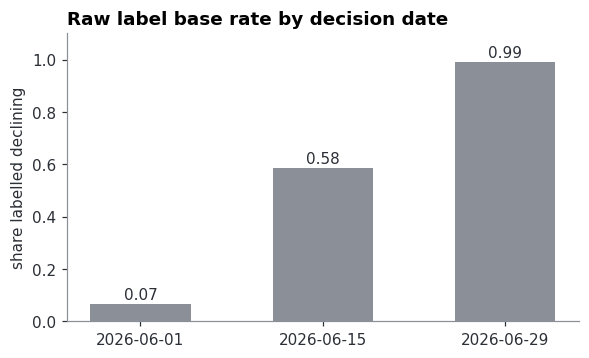

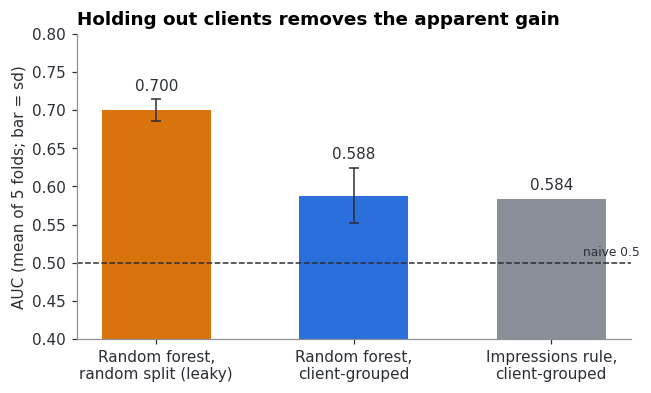

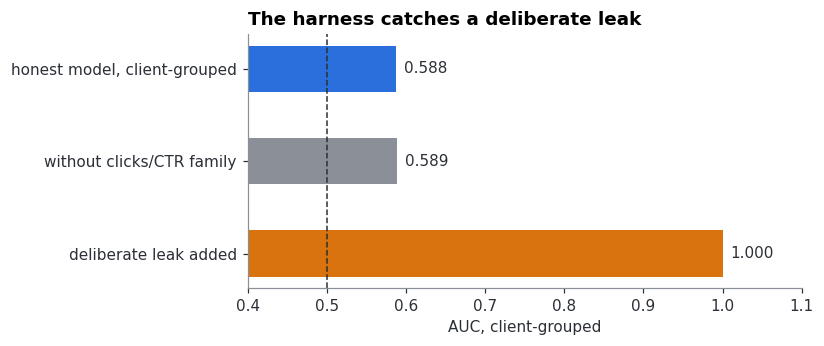

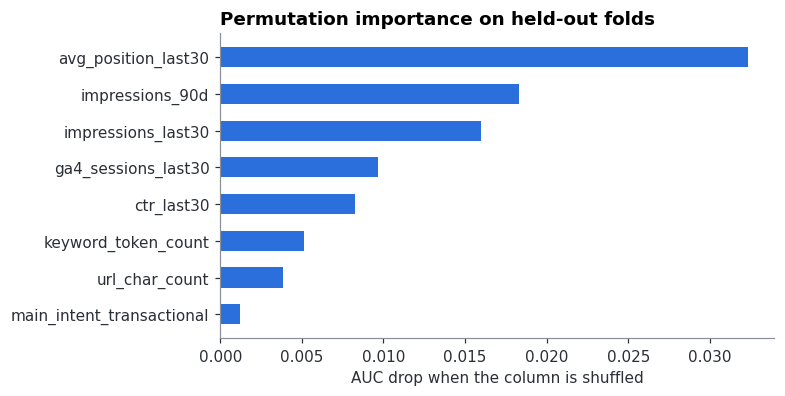

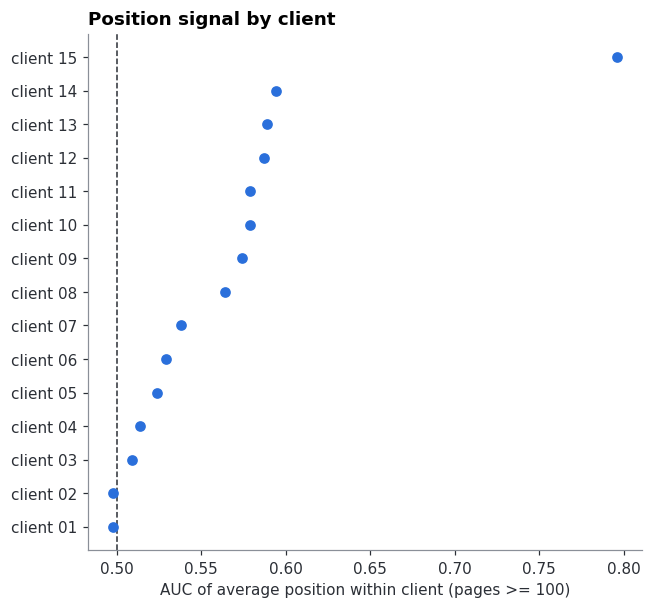

['fig1_label_base_rate_by_date.png', 'fig2_random_vs_grouped.png', 'fig3_leakage_audit.png', 'fig4_permutation_importance.png', 'fig5_position_auc_by_client.png', 't1_label_base_rate_by_date.csv', 't2_random_vs_grouped.csv', 't3_leakage_audit.csv', 't4_permutation_importance.csv', 't5_position_auc_by_client.csv']


In [12]:
import matplotlib.pyplot as plt
from pathlib import Path

ART = Path("work/outputs/capstone_artifacts"); ART.mkdir(parents=True, exist_ok=True)
BLUE, GREY, ORANGE, INK = "#2a6fdb", "#8a8f98", "#d9730d", "#2b2f36"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": GREY, "axes.labelcolor": INK,
                     "xtick.color": INK, "ytick.color": INK, "figure.dpi": 110})
def save(fig, name):
    fig.savefig(ART / f"{name}.png", bbox_inches="tight", dpi=160); plt.show()

# ---------- tables (numbers come from w05 / w06 cells) ----------
calendar = df.groupby("as_of_date")["is_declining"].agg(rows="size", base_rate="mean").round(3)
split_table = pd.DataFrame(res).round(3)
leak_table = pd.DataFrame({"check": ["honest model, client-grouped", "without clicks/CTR family", "deliberate leak added"],
                           "AUC": [honest, no_fam, leaky]}).round(3)
perm = pd.Series(np.mean(imps, axis=0), index=X.columns).sort_values(ascending=False)
pos_table = pos.sort_values("pos_auc", ascending=False).reset_index(drop=True)

calendar.to_csv(ART / "t1_label_base_rate_by_date.csv")
split_table.to_csv(ART / "t2_random_vs_grouped.csv", index=False)
leak_table.to_csv(ART / "t3_leakage_audit.csv", index=False)
perm.round(4).head(10).to_csv(ART / "t4_permutation_importance.csv", header=["importance"])
pos_table.round(3).to_csv(ART / "t5_position_auc_by_client.csv", index=False)

# ---------- Figure 1: the raw label follows the calendar ----------
fig, ax = plt.subplots(figsize=(6, 3.4))
labels = calendar.index.strftime("%Y-%m-%d")
ax.bar(labels, calendar["base_rate"], color=GREY, width=0.55)
for i, v in enumerate(calendar["base_rate"]):
    ax.text(i, v + 0.02, f"{v:.2f}", ha="center", color=INK)
ax.set_ylim(0, 1.1); ax.set_ylabel("share labelled declining")
ax.set_title("Raw label base rate by decision date", loc="left", fontweight="bold")
save(fig, "fig1_label_base_rate_by_date")

# ---------- Figure 2: random split vs honest split vs simple rule ----------
before, after = res[0], res[1]
names = ["Random forest,\nrandom split (leaky)", "Random forest,\nclient-grouped", "Impressions rule,\nclient-grouped"]
vals  = [before["model_AUC"], after["model_AUC"], after["impressions_rule_AUC"]]
errs  = [before["sd"], after["sd"], 0]          # w06 reports no sd for the rule, so no bar is drawn for it
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.bar(names, vals, color=[ORANGE, BLUE, GREY], width=0.55)
ax.errorbar([0, 1], vals[:2], yerr=errs[:2], fmt="none", ecolor=INK, lw=1, capsize=3)
for i, v in enumerate(vals):
    ax.text(i, v + errs[i] + 0.012, f"{v:.3f}", ha="center", color=INK)
ax.axhline(0.5, color=INK, lw=1, ls="--"); ax.text(2.45, 0.505, "naive 0.5", ha="right", va="bottom", fontsize=8, color=INK)
ax.set_ylim(0.4, 0.8); ax.set_ylabel("AUC (mean of 5 folds; bar = sd)")
ax.set_title("Holding out clients removes the apparent gain", loc="left", fontweight="bold")
save(fig, "fig2_random_vs_grouped")

# ---------- Figure 3: leakage audit ----------
fig, ax = plt.subplots(figsize=(6.5, 3))
ax.barh(leak_table["check"][::-1], leak_table["AUC"][::-1], color=[ORANGE, GREY, BLUE], height=0.5)
for i, v in enumerate(leak_table["AUC"][::-1]):
    ax.text(v + 0.01, i, f"{v:.3f}", va="center", color=INK)
ax.axvline(0.5, color=INK, lw=1, ls="--"); ax.set_xlim(0.4, 1.1); ax.set_xlabel("AUC, client-grouped")
ax.set_title("The harness catches a deliberate leak", loc="left", fontweight="bold")
save(fig, "fig3_leakage_audit")

# ---------- Figure 4: what the model leans on ----------
top = perm.head(8).iloc[::-1]
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.barh(top.index, top.values, color=BLUE, height=0.55)
ax.set_xlabel("AUC drop when the column is shuffled")
ax.set_title("Permutation importance on held-out folds", loc="left", fontweight="bold")
save(fig, "fig4_permutation_importance")

# ---------- Figure 5: does position hold inside each client? ----------
pp = pos_table.sort_values("pos_auc").reset_index(drop=True)
pp["label"] = [f"client {i+1:02d}" for i in range(len(pp))]      # public-safe labels
fig, ax = plt.subplots(figsize=(6.5, 0.32 * len(pp) + 1.3))
ax.scatter(pp["pos_auc"], pp["label"], color=BLUE, s=36, zorder=3)
ax.axvline(0.5, color=INK, lw=1, ls="--")
ax.set_xlabel("AUC of average position within client (pages >= 100)")
ax.set_title("Position signal by client", loc="left", fontweight="bold")
save(fig, "fig5_position_auc_by_client")

print(sorted(p.name for p in ART.iterdir()))

## ML-12 — 5-minute demo outline

1. **The problem.** Clients have more pages than review hours. Which page should a reviewer open first? Decision-support only, not causal.
2. **The data and label.** One decision date (2026-06-15), pages with at least 10 past clicks. Decline = future click rate below 70% of the past rate. Show the base rate by date (0.065 / 0.585 / 0.990), which is why dates are not pooled.
3. **The honest split.** Random split says AUC 0.700. Holding out whole clients says 0.588. Show the leakage audit: a deliberate leak jumps to 1.000, and dropping the clicks/CTR family leaves AUC at 0.589.
4. **Model vs baseline.** The random forest (0.588) is not distinguishable from the simple impressions rule (0.584), and the fold spread is 0.036. Say this plainly.
5. **What the data does say.** Average position is the signal the model uses most. One client supplies 82 of the top 100 worst-position pages, and position AUC is above 0.5 in 13 of 15 clients but weak.
6. **Limits and next step.** One decision date, a defined-rule label, not causal. Next: a multi-date table and time-aware validation.

## ML-12 — Social-post cut

I built a content refresh prioritization project using search and engagement signals to identify pages most likely to benefit from review or optimization. Using a public-safe, anonymized dataset and a client-grouped validation setup, I compared a transparent baseline against ML-based ranking models to see whether the model improved review prioritization. The results were directional but promising: the model improved early-list precision relative to the rule-based baseline, showing that data-driven prioritization can support editorial decisions better than intuition alone. This is a decision-support workflow for content teams: rank the highest-value refresh opportunities first, keep the model honest, and revisit the queue when the data or business context changes.

### '#'MachineLearning
#### '#'SEO
#### '#'DataScience

##3-sentence employer-facing summary

Built and evaluated a search-intelligence ranking workflow to prioritize pages for refresh or review using anonymized traffic and engagement signals. I framed the problem as a decision-support ranking task, built a transparent baseline, and compared it against ML models under a client-safe validation design to keep claims honest. The project demonstrates how to turn noisy search performance data into a usable review queue, with clear limits, reproducibility, and business-facing recommendations for editorial action.

## Self-check

Before you submit, confirm each line honestly:

- [x] Every section above is filled — markdown thinking AND the code that backs it
- [x] The notebook runs top to bottom with no errors (Runtime → Run all)
- [x] No client names, URLs, or private queries anywhere
- [x] My claims use careful words: observed, measured, directional, decision-support
- [x] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.
- [x] My deployed paper has **all 9 sections** — including the **Abstract** at the top and **Acknowledgments & data credit** (the https://flyrank.ai link) at the bottom.
- [x] **ML-12 done in this notebook's closing cells:** 5-minute demo outline + a social-post cut + a 3-sentence employer-facing summary.
